# Covarianza de los estimadores de $\xi(r)$ con dilución de materia oscura

Sigo los pasos de `plan_proyecto.md`: crecimiento con dilución $\to$ $P_{\rm dil}(k)$ $\to$ campos gaussianos $\to$ $\hat\xi(r)$ con cuatro estimadores $\to$ covarianza, para $g_0=0$ ($\Lambda$CDM) y $g_0=0.2$.

## 1. Crecimiento lineal

La ecuación de $D_+$ con el toy model, escrita en $\ln a$ ($'=d/d\ln a$):

$$D_+'' + \left(2 + \frac{d\ln H}{d\ln a} + g\right)D_+' - \left[\frac32\Omega_m - g\left(2 + \frac{d\ln H}{d\ln a}\right) - g'\right]D_+ = 0,$$

$$g(z) = \frac{g_0}{2}\left[1 - \tanh\left(\frac{z - z_t}{\Delta z}\right)\right].$$

El fondo ($H$ y $\Omega_m$) sale de CLASS y es el mismo para los dos modelos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class
from scipy.interpolate import CubicSpline
from scipy.integrate import solve_ivp

plt.rcParams['font.size'] = 14

Om0, Ob0, h, ns, sigma8 = 0.3, 0.045, 0.7, 0.965, 0.8

cosmo = Class()
cosmo.set({'output': 'mPk', 'h': h, 'omega_b': Ob0*h**2, 'omega_cdm': (Om0 - Ob0)*h**2,
           'n_s': ns, 'sigma8': sigma8, 'P_k_max_h/Mpc': 20.0, 'z_max_pk': 1.0})
cosmo.compute()

bg = cosmo.get_background()
lna, i = np.unique(-np.log1p(bg['z']), return_index=True)    # CLASS va de z alto a z = 0
lnH = CubicSpline(lna, np.log(bg['H [1/Mpc]'][i]))
Om = CubicSpline(lna, ((bg['(.)rho_cdm'] + bg['(.)rho_b'])/bg['(.)rho_crit'])[i])
D_class = CubicSpline(lna, bg['gr.fac. D'][i])
f_class = CubicSpline(lna, bg['gr.fac. f'][i])
dlnH = lnH.derivative()

In [2]:
zt, dz = 2.0, 0.2

def g(z, g0):
    return g0/2*(1 - np.tanh((z - zt)/dz))

def dg(z, g0):    # dg/dln a
    return (1 + z)*g0/(2*dz)*(1 - np.tanh((z - zt)/dz)**2)

def crecimiento(g0, z_ini=99):
    def rhs(x, y):
        z = np.exp(-x) - 1
        e = dlnH(x)
        D, dD = y
        return [dD, -(2 + e + g(z, g0))*dD + (1.5*Om(x) - g(z, g0)*(2 + e) - dg(z, g0))*D]
    x0 = -np.log1p(z_ini)                     # en z = 99 todavía g = 0: parto de D y f de CLASS
    y0 = [D_class(x0), f_class(x0)*D_class(x0)]
    sol = solve_ivp(rhs, [x0, 0], y0, dense_output=True, rtol=1e-10, atol=1e-13)
    return lambda z: sol.sol(-np.log1p(z))[0]

D_LCDM = crecimiento(0.0)
D_dil = crecimiento(0.2)

zs = np.array([0, 0.5, 1, 2, 5])
print(f'max |D_LCDM/D_CLASS - 1| = {np.abs(D_LCDM(zs)/D_class(-np.log1p(zs)) - 1).max():.1e}')

z_obs = 0.5
ratio = (D_dil(z_obs)/D_LCDM(z_obs))**2
print(f'P_dil/P_LCDM en z = {z_obs}: {ratio:.4f}')

max |D_LCDM/D_CLASS - 1| = 2.0e-09
P_dil/P_LCDM en z = 0.5: 0.7999


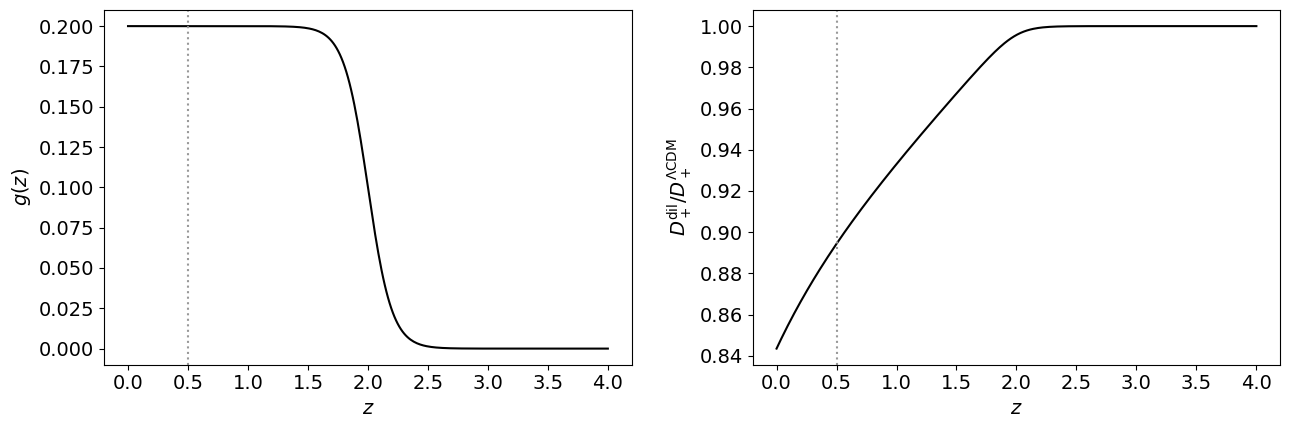

In [3]:
z = np.linspace(0, 4, 300)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(z, g(z, 0.2), 'k-', lw=1.5)
axs[0].set(xlabel='$z$', ylabel='$g(z)$')
axs[1].plot(z, D_dil(z)/D_LCDM(z), 'k-', lw=1.5)
axs[1].set(xlabel='$z$', ylabel=r'$D_+^{\rm dil}/D_+^{\Lambda\rm CDM}$')
for ax in axs:
    ax.axvline(z_obs, color='0.6', ls=':')
fig.tight_layout()
plt.show()

Con $g_0=0$ se recupera el $D_+$ de CLASS (diferencia $\sim10^{-9}$). Con $g_0=0.2$ el crecimiento se frena a partir de $z_t=2$ y en $z=0.5$ queda $P_{\rm dil}/P_{\Lambda\rm CDM}=0.80$.

## 2. Espectro con dilución

$$P_{\rm dil}(k) = \left[\frac{D_+^{\rm dil}(z)}{D_+^{\Lambda\rm CDM}(z)}\right]^2 P_L(k, z),$$

con $P_L$ de CLASS en $z=0.5$.

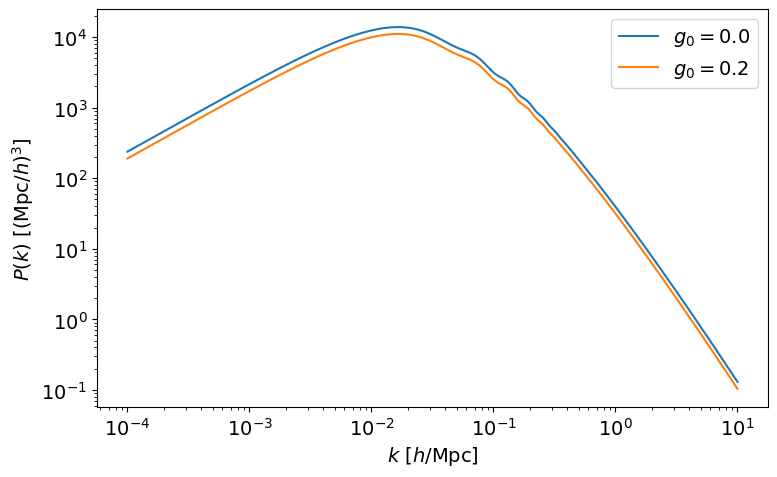

In [4]:
G0 = [0.0, 0.2]

k = np.logspace(-4, 1, 2000)                                     # h/Mpc
P_L = np.array([cosmo.pk_lin(ki*h, z_obs) for ki in k])*h**3     # (Mpc/h)^3
P = {0.0: P_L, 0.2: ratio*P_L}

plt.figure(figsize=(8, 5))
for g0 in G0:
    plt.loglog(k, P[g0], lw=1.5, label=f'$g_0={g0}$')
plt.xlabel('$k$ [$h$/Mpc]')
plt.ylabel('$P(k)$ [(Mpc/$h$)$^3$]')
plt.legend()
plt.tight_layout()
plt.show()

## 3. Campos gaussianos y catálogos

Caja periódica de $L=1000\,h^{-1}$Mpc con malla $128^3$. Como en las prácticas, el campo se arma en Fourier, pero partiendo de ruido blanco real $w$ en la malla:

$$\delta(\mathbf k) = \sqrt{P(k)/V_{\rm celda}}\;\mathrm{FFT}[w],$$

así la condición $\delta(-\mathbf k)=\delta^*(\mathbf k)$ se cumple sola.

In [5]:
from scipy import fft

L, N = 1000.0, 128
Vcell = (L/N)**3

kx = 2*np.pi*fft.fftfreq(N, d=L/N)
kz = 2*np.pi*fft.rfftfreq(N, d=L/N)
K = np.sqrt(kx[:, None, None]**2 + kx[None, :, None]**2 + kz[None, None, :]**2)

Pmalla = {g0: np.interp(K, k, P[g0]) for g0 in G0}
for g0 in G0:
    Pmalla[g0][0, 0, 0] = 0                  # sin modo k = 0

def campo_gaussiano(Pk, rng):
    w = rng.standard_normal((N, N, N))
    return fft.irfftn(fft.rfftn(w)*np.sqrt(Pk/Vcell), s=(N, N, N))

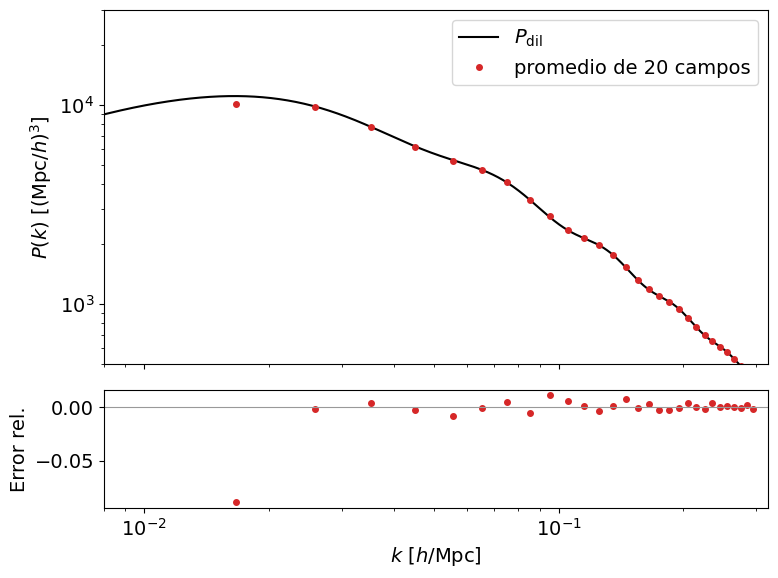

In [6]:
# validación: <|δ(k)|²> en 20 realizaciones contra P_dil
k_edges = np.arange(0.01, 0.31, 0.01)
nmodos = np.histogram(K, k_edges)[0]
k_bin = np.histogram(K, k_edges, weights=K)[0]/nmodos

Pk_med = np.zeros(len(k_bin))
for s in range(20):
    dk = fft.rfftn(campo_gaussiano(Pmalla[0.2], np.random.default_rng(s)))
    Pk_med += np.histogram(K, k_edges, weights=np.abs(dk)**2)[0]/nmodos*Vcell**2/L**3/20

fig, (ax, ax_err) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, height_ratios=[3, 1])
ax.loglog(k, P[0.2], 'k-', lw=1.5, label=r'$P_{\rm dil}$')
ax.loglog(k_bin, Pk_med, 'o', ms=4, color='C3', label='promedio de 20 campos')
ax.set(xlim=(0.008, 0.32), ylim=(5e2, 3e4), ylabel='$P(k)$ [(Mpc/$h$)$^3$]')
ax.legend()
ax_err.plot(k_bin, Pk_med/np.interp(k_bin, k, P[0.2]) - 1, 'o', ms=4, color='C3')
ax_err.axhline(0, color='0.6', lw=0.8)
ax_err.set(xlabel='$k$ [$h$/Mpc]', ylabel='Error rel.')
fig.tight_layout()
plt.show()

El promedio sigue a $P_{\rm dil}$ a menos del 1 %. El primer bin se desvía más porque tiene muy pocos modos.

### 3.1. Puntos

El $\delta$ gaussiano puede ser $<-1$, así que para la densidad uso $1+\delta \to e^{\delta-\sigma^2/2}$. En cada celda pongo un número Poisson de puntos con media $\bar n V_{\rm celda}\,e^{\delta-\sigma^2/2}$, en posiciones uniformes dentro de la celda.

In [7]:
nbar = 5e-5    # (h/Mpc)^3

def puntos(delta, rng):
    n = rng.poisson(nbar*Vcell*np.exp(delta - delta.var()/2))
    celda = np.repeat(np.arange(n.size), n.ravel())
    ijk = np.column_stack(np.unravel_index(celda, n.shape))
    return (ijk + rng.uniform(size=ijk.shape))*L/N

rng = np.random.default_rng(42)
delta = campo_gaussiano(Pmalla[0.0], rng)
D = puntos(delta, rng)
print(f'N_D = {len(D)},  nbar*V = {nbar*L**3:.0f}')

N_D = 50049,  nbar*V = 50000


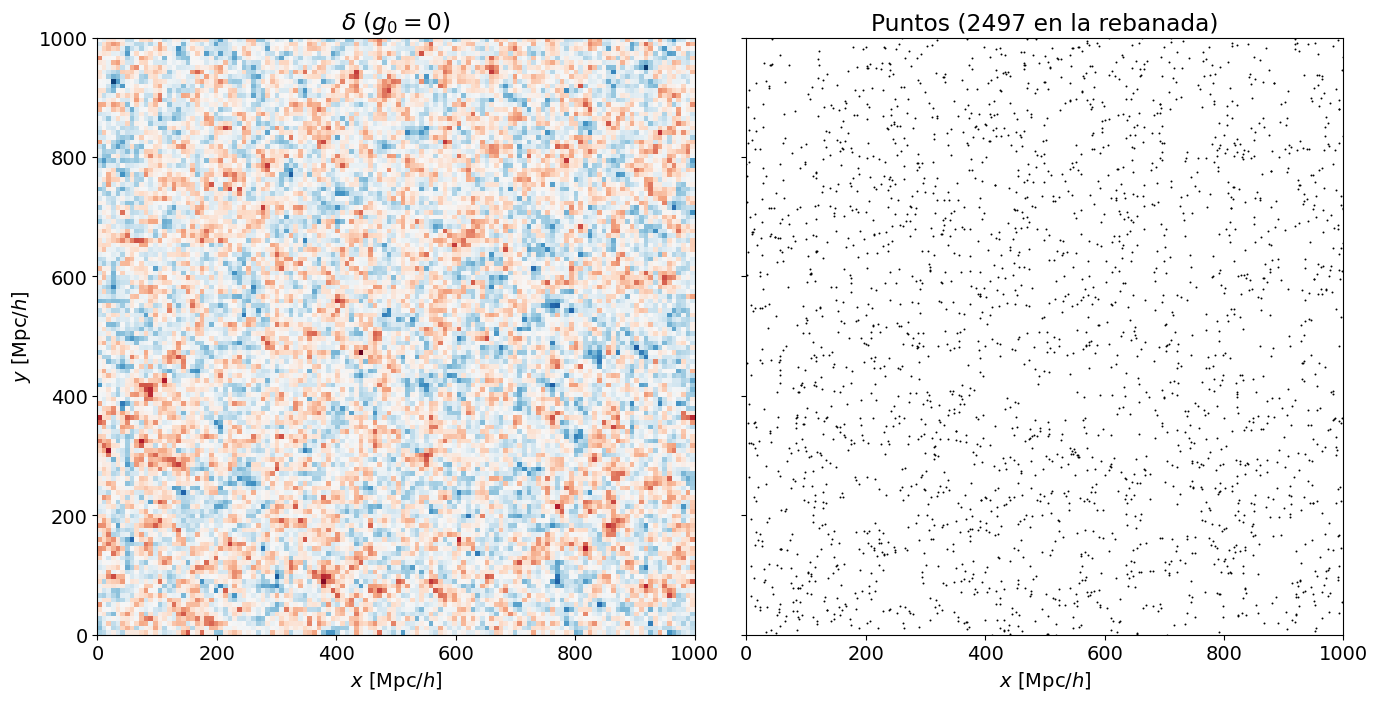

In [8]:
corte = D[:, 2] < 50     # rebanada de 50 Mpc/h

fig, axs = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
vmax = np.abs(delta[:, :, :6]).mean(axis=2).max()
axs[0].imshow(delta[:, :, :6].mean(axis=2).T, origin='lower', extent=[0, L, 0, L],
              cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axs[0].set(xlabel='$x$ [Mpc/$h$]', ylabel='$y$ [Mpc/$h$]', title=r'$\delta$ ($g_0=0$)')
axs[1].scatter(D[corte, 0], D[corte, 1], s=2, c='k', linewidths=0)
axs[1].set(xlabel='$x$ [Mpc/$h$]', title=f'Puntos ({corte.sum()} en la rebanada)', aspect='equal')
fig.tight_layout()
plt.show()

### 3.2. Aleatorios

$N_R = \alpha N_D$ con $\alpha = 1$ y $3$. Uso los mismos aleatorios en todas las realizaciones, así que $RR$ se calcula una vez.

In [9]:
ND = int(nbar*L**3)
alphas = [1, 3]
R = {a: rng.uniform(0, L, (a*ND, 3)) for a in alphas}

## 4. Estimadores de $\xi(r)$

Igual que en la práctica 05, pero el conteo de pares es con `cKDTree(boxsize=L)` por la periodicidad. $DD$, $DR$ y $RR$ van normalizados por el número de pares:

$$\hat\xi_{\rm PH} = \frac{DD}{RR}-1,\qquad \hat\xi_{\rm DP} = \frac{DD}{DR}-1,\qquad \hat\xi_{\rm Ham} = \frac{DD\,RR}{DR^2}-1,\qquad \hat\xi_{\rm LS} = \frac{DD-2DR+RR}{RR}.$$

In [10]:
from scipy.spatial import cKDTree

r_edges = np.arange(20, 155, 5)      # Mpc/h
r = (r_edges[1:] + r_edges[:-1])/2

def pares(A, B=None):
    tA = cKDTree(A, boxsize=L)
    if B is None:
        return np.diff(tA.count_neighbors(tA, r_edges))/(len(A)*(len(A) - 1))
    return np.diff(tA.count_neighbors(cKDTree(B, boxsize=L), r_edges))/(len(A)*len(B))

EST = {'PH':  lambda DD, DR, RR: DD/RR - 1,
       'DP':  lambda DD, DR, RR: DD/DR - 1,
       'Ham': lambda DD, DR, RR: DD*RR/DR**2 - 1,
       'LS':  lambda DD, DR, RR: (DD - 2*DR + RR)/RR}

RR = {a: pares(R[a]) for a in alphas}

def realizacion(s, g0):
    rng = np.random.default_rng(s)       # misma semilla para g0 = 0 y g0 = 0.2
    D = puntos(campo_gaussiano(Pmalla[g0], rng), rng)
    DD = pares(D)
    xi = {}
    for a in alphas:
        DR = pares(D, R[a])
        for e in EST:
            xi[e, a] = EST[e](DD, DR, RR[a])
    return xi

El $\xi$ teórico, para comparar:

$$\xi(r) = \int_0^\infty \frac{k^2\,dk}{2\pi^2}\,P(k)\,j_0(kr).$$

In [11]:
kk = np.linspace(1e-4, 5, 50000)

def xi_teo(Pk):
    Pkk = np.interp(kk, k, Pk)*np.exp(-kk**2)      # e^{-k²} solo para que converja; no cambia r ≥ 20
    j0 = np.sinc(kk[:, None]*r/np.pi)              # sin(kr)/(kr)
    return np.trapezoid(kk[:, None]**2*Pkk[:, None]*j0, kk, axis=0)/(2*np.pi**2)

xi_t = {g0: xi_teo(P[g0]) for g0 in G0}

una realización: 12.1 s


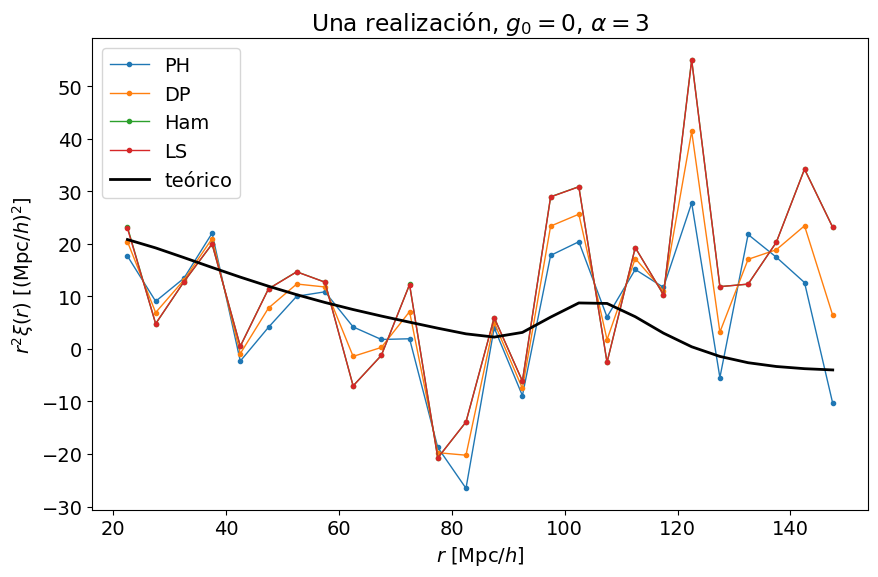

In [12]:
import time

t0 = time.time()
xi1 = realizacion(0, 0.0)
print(f'una realización: {time.time() - t0:.1f} s')

plt.figure(figsize=(9, 6))
for e in EST:
    plt.plot(r, r**2*xi1[e, 3], '-o', ms=3, lw=1, label=e)
plt.plot(r, r**2*xi_t[0.0], 'k-', lw=2, label='teórico')
plt.xlabel('$r$ [Mpc/$h$]')
plt.ylabel(r'$r^2\xi(r)$ [(Mpc/$h$)$^2$]')
plt.title(r'Una realización, $g_0=0$, $\alpha=3$')
plt.legend()
plt.tight_layout()
plt.show()

Una sola caja es muy ruidosa y el pico BAO casi no se distingue. Los cuatro estimadores se mueven juntos porque comparten el mismo $DD$; Hamilton y LS prácticamente coinciden.

### 4.1. $N$ realizaciones

El conteo de pares es lo caro, así que reparto las realizaciones en varios procesos.

In [13]:
from multiprocessing import Pool

Nreal = 100

t0 = time.time()
xi = {}
with Pool(8) as pool:
    for g0 in G0:
        res = pool.starmap(realizacion, [(s, g0) for s in range(Nreal)])
        for key in res[0]:
            xi[(g0, *key)] = np.array([x[key] for x in res])      # xi[g0, est, alpha]: (Nreal, bins)
print(f'{len(G0)*Nreal} realizaciones en {time.time() - t0:.0f} s')

np.savez('data/xi_estimadores.npz', r=r, **{f'{g0}_{e}_{a}': xi[g0, e, a] for (g0, e, a) in xi})

200 realizaciones en 386 s


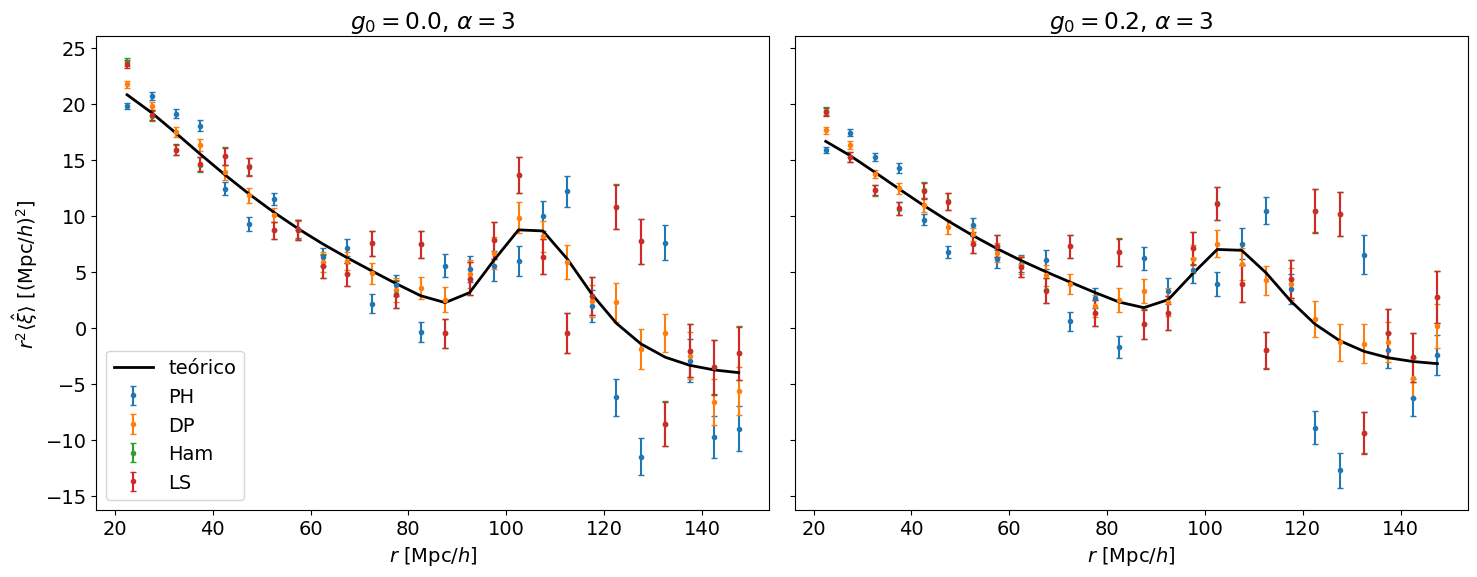

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, g0 in zip(axs, G0):
    for e in EST:
        X = xi[g0, e, 3]
        ax.errorbar(r, r**2*X.mean(0), r**2*X.std(0)/np.sqrt(Nreal), fmt='o', ms=3, capsize=2, label=e)
    ax.plot(r, r**2*xi_t[g0], 'k-', lw=2, label='teórico')
    ax.set(xlabel='$r$ [Mpc/$h$]', title=rf'$g_0={g0}$, $\alpha=3$')
axs[0].set_ylabel(r'$r^2\langle\hat\xi\rangle$ [(Mpc/$h$)$^2$]')
axs[0].legend()
fig.tight_layout()
plt.show()

Los promedios siguen al teórico, incluido el pico BAO en $\sim105\,h^{-1}$Mpc, y con $g_0=0.2$ la amplitud baja. Las diferencias entre estimadores en un mismo bin (por ejemplo PH contra LS en 120–130 $h^{-1}$Mpc) se repiten igual en los dos modelos: vienen de usar los mismos aleatorios en todas las realizaciones, así que el ruido de $RR$ y $DR$ no se promedia y queda como un sesgo. Las barras ($\sigma/\sqrt N$) no lo incluyen.

## 5. Covarianza muestral

$$\hat C_{ij} = \frac{1}{N-1}\sum_{s=1}^{N}(\hat\xi_{s,i}-\bar\xi_i)(\hat\xi_{s,j}-\bar\xi_j),\qquad r_{ij} = \frac{\hat C_{ij}}{\sqrt{\hat C_{ii}\hat C_{jj}}}.$$

Con $N=100$, el error relativo de cada elemento es $\sim\sqrt{2/N}\approx0.14$.

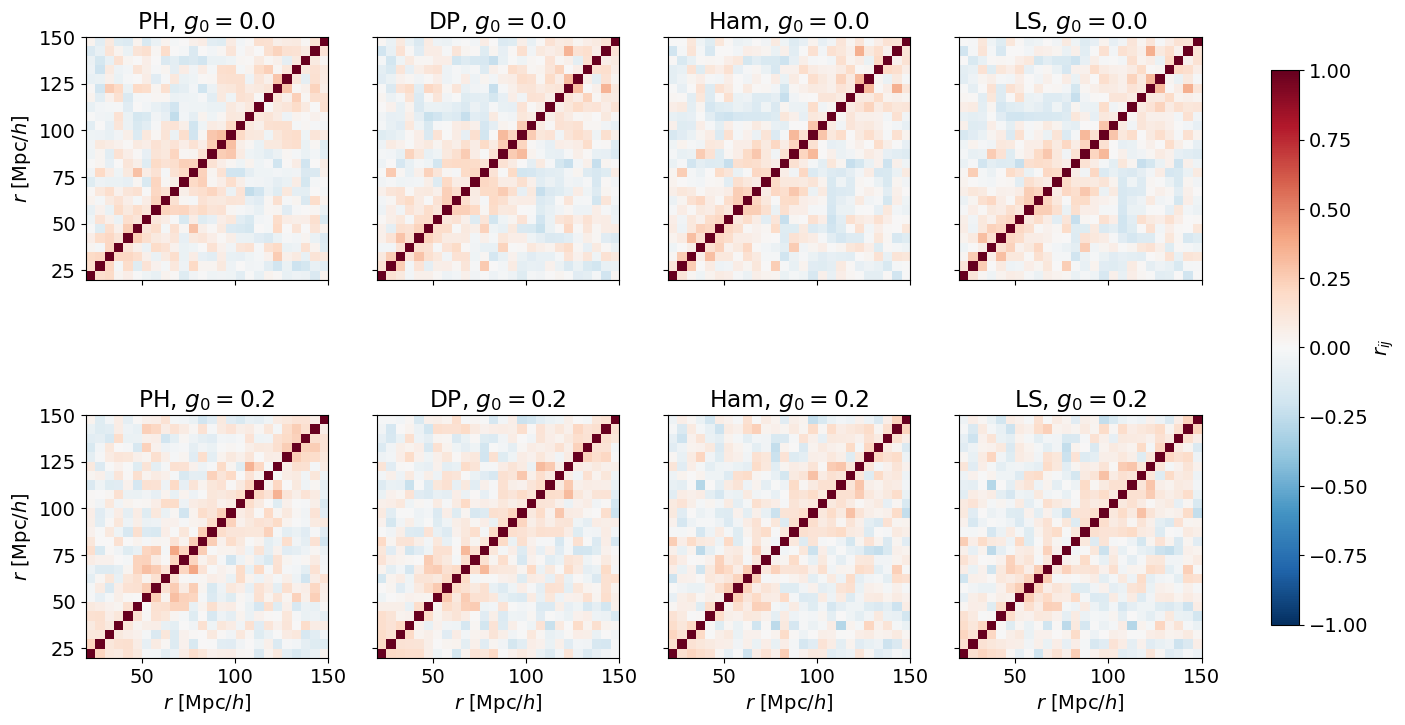

In [15]:
C = {key: np.cov(xi[key], rowvar=False) for key in xi}

fig, axs = plt.subplots(2, 4, figsize=(18, 9), sharex=True, sharey=True)
for row, g0 in zip(axs, G0):
    for ax, e in zip(row, EST):
        im = ax.imshow(np.corrcoef(xi[g0, e, 3], rowvar=False), origin='lower', cmap='RdBu_r',
                       vmin=-1, vmax=1, extent=[r_edges[0], r_edges[-1], r_edges[0], r_edges[-1]])
        ax.set_title(rf'{e}, $g_0={g0}$')
for ax in axs[1]:
    ax.set_xlabel('$r$ [Mpc/$h$]')
for ax in axs[:, 0]:
    ax.set_ylabel('$r$ [Mpc/$h$]')
fig.colorbar(im, ax=axs, shrink=0.8, label='$r_{ij}$')
plt.show()

Las matrices salen casi diagonales. Fuera de la diagonal solo queda una correlación pequeña entre bins vecinos ($\approx0.15$) y ruido de $\pm0.1\approx1/\sqrt N$.

## 6. Comparaciones

### 6.1. Entre estimadores

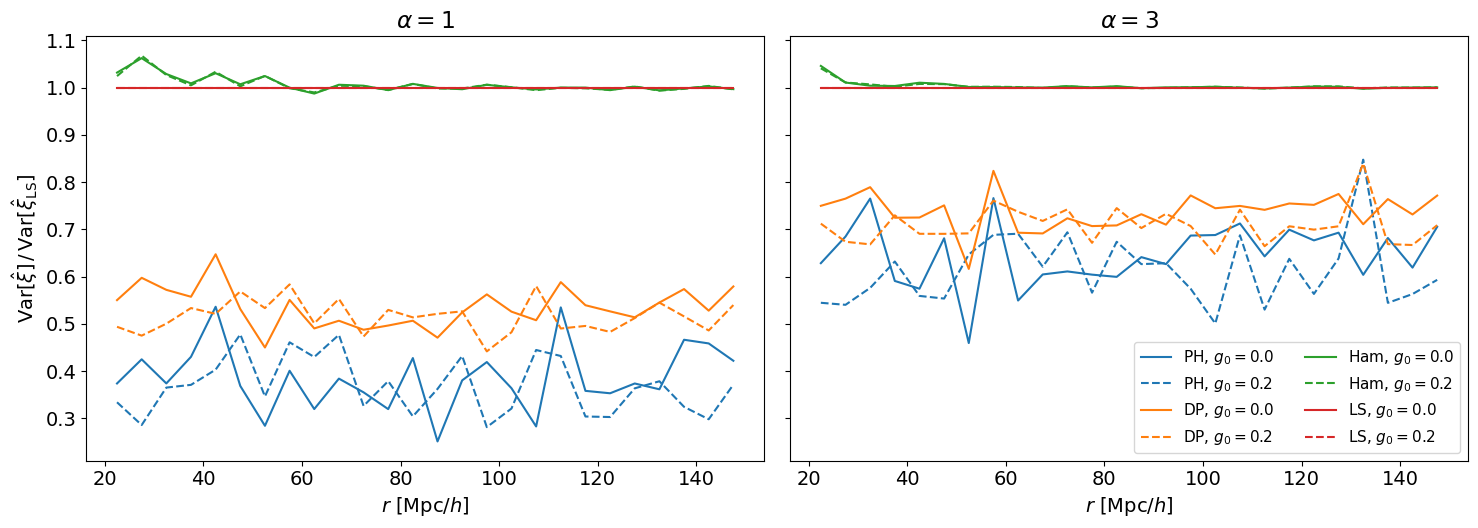

alpha = 1: PH 0.39, DP 0.54, Ham 1.01, LS 1.00
alpha = 3: PH 0.65, DP 0.74, Ham 1.00, LS 1.00


In [16]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, a in zip(axs, alphas):
    for c, e in enumerate(EST):
        for g0, ls in zip(G0, ['-', '--']):
            ax.plot(r, np.diag(C[g0, e, a])/np.diag(C[g0, 'LS', a]), ls, color=f'C{c}',
                    label=f'{e}, $g_0={g0}$')
    ax.set(xlabel='$r$ [Mpc/$h$]', title=rf'$\alpha={a}$')
axs[0].set_ylabel(r'${\rm Var}[\hat\xi]\,/\,{\rm Var}[\hat\xi_{\rm LS}]$')
axs[1].legend(fontsize=11, ncol=2)
fig.tight_layout()
plt.show()

for a in alphas:
    print(f'alpha = {a}:', ', '.join(f'{e} {np.mean(np.diag(C[0.0, e, a])/np.diag(C[0.0, "LS", a])):.2f}' for e in EST))

Con aleatorios fijos, $RR$ es el mismo en todas las realizaciones y la varianza de PH viene solo de $DD$; DP, Hamilton y LS además cargan con el ruido de $DR$. Por eso PH sale con la menor varianza y Hamilton $\approx$ LS. Al pasar de $\alpha=1$ a $\alpha=3$ el ruido de $DR$ baja y los cocientes se acercan a 1. En una caja periódica no hay bordes, así que la ventaja usual de LS no aparece. Entre $g_0=0$ y $g_0=0.2$ los cocientes casi no cambian.

### 6.2. Entre modelos

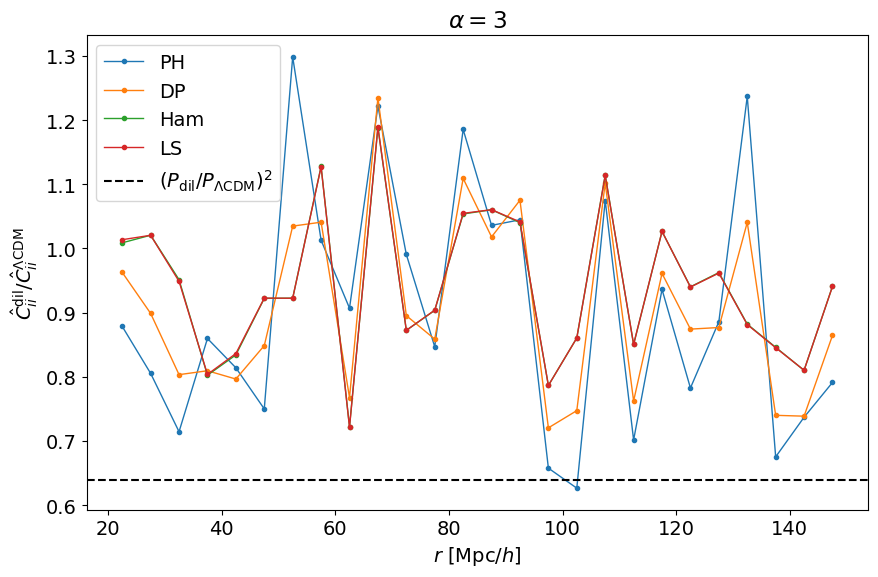

In [17]:
plt.figure(figsize=(9, 6))
for e in EST:
    plt.plot(r, np.diag(C[0.2, e, 3])/np.diag(C[0.0, e, 3]), '-o', ms=3, lw=1, label=e)
plt.axhline(ratio**2, color='k', ls='--', label=r'$(P_{\rm dil}/P_{\Lambda\rm CDM})^2$')
plt.xlabel('$r$ [Mpc/$h$]')
plt.ylabel(r'$\hat C_{ii}^{\rm dil}/\hat C_{ii}^{\Lambda\rm CDM}$')
plt.title(r'$\alpha=3$')
plt.legend()
plt.tight_layout()
plt.show()

En promedio, la varianza con dilución es $\approx0.90$ (PH, DP) y $\approx0.94$ (Hamilton, LS) de la de $\Lambda$CDM, lejos de $0.64$: solo la parte de varianza cósmica escala como $P^2$, y con $\bar n=5\times10^{-5}$ domina el ruido de Poisson, que no se diluye. Bin a bin el cociente es ruidoso, porque cada varianza tiene un error de $\sim\sqrt{2/N}$.